### Notebook to test different elements of the script 

🎯 The goal is to reproduce the figures from *Jiang and Litwin-Kumar (2021)*.

‼️**IMPORTANT**: If you are running this notebook for the first time, please make sure to install the required packages by running the following lines in your terminal:
1. Activate your environment: 
* Windows (PowerShell): ``.venv\Scripts\Activate.ps1``
* macOS / Linux (Bash): ``source .venv/bin/activate``
2. Install the requirements: ``python -m pip install -r requirements.txt``

🚩 @ TODO : might want to add a step to create environment, also the "activate your environment" might vary if user is using conda or virtual environment... need to verify.

In [20]:
## Imports
import numpy as np
import torch
import matplotlib.pyplot as plt
from test_modules.plasticity import *
import definemodel as model_parameters

#### Fig. 1. B - Dopamine neuron-gated plasticity rule for $W_{KC\rightarrow MBON}$

This figure shows $\Delta W_{KC\rightarrow MBON}$ the change in weights from an example *j-th* KC to *i-th* MBON neuron as a function of $\Delta W$ the time difference between **Kenyon cell** activation and **dopamine neuron** activation : $\Delta T = t_{DAN} - t_{KC}$. 

* If $\Delta T > 0$, we have **forward pairing** (KC first, then DAN): there is an increasingly larger positive change in weights until $T=0$; if the KC activation is prior than 10 seconds before the DAN activation, then the weight difference tends to zero and no association is being formed, while smaller negative time difference correspond to large positive weight differences. 
* If $\Delta T < 0$, we have **backward pairing** (DAN first, then KC): a negative weight difference that starts at the maximum magnitude but at a negative value and tends to zero as the time difference increases, which makes for no association being created.

To track the change in $W_{KC \rightarrow MBON}$ we need to look at this part of the article (page 5):

>We therefore augmented our networks with a model of this plasticity by assuming that each element of $W_{KC \rightarrow MBON}$ is a dynamic quantity that tracks the variables $w_{ij}$ (with a time constant of $\tau_W$ = 5 s). These variables, which determine the strength of the connection from the jth Kenyon cell to the ith output neuron, obey the following update rule:
> $$ \frac{dw_{ij}(t)}{dt} = \bar{r}_i^{DAN}(t)r_j(t) - \bar{r}_j^{KC}(t)r_i^{DAN}(t)$$
> Each element of $W_{KC \rightarrow MBON}$ is initially set to its maximum value of 0.05 and subsequently updated according to
> $$ \tau_W \frac{dW^{KC \rightarrow MBON}_{ij}(t)}{dt}= W^{KC \rightarrow MBON}_{ij}(t) + w_{ij}(t)$$

In [ ]:
# Construct the array of time differences between pulses of activation
dT_win_start = -10 # (in seconds)
dT_win_end = 10 # (in seconds)
dT_win_num = dT_win_end - dT_win_start + 1
dT_array = np.linspace(start=dT_win_start, stop=dT_win_end, num=dT_win_num)

# Define time range of the experience
time_range_end = 60 # (in seconds)
dt = model_parameters.dt # (in seconds)
time_range = np.arange(0, time_range_end, dt)

# Import the model parameters
tau = model_parameters.tau
tauw = model_parameters.tauw
wmax = model_parameters.wmax
stdpfac = model_parameters.stdpfac

# For this figure, we simulate only one KC, one MBON, and one DAN neuron
n_kc = 1
n_mbon = 1
n_dan = 1

# Define the batch size as 1
batch_size = 1

# Initialize the pulses and weights
pulse_kc = np.zeros((n_kc, len(time_range), batch_size))
pulse_dan = np.zeros((n_dan, len(time_range), batch_size))

# The DAN pulse is kept as a reference and we sweep through the KC pulse
t_dan_init = time_range_end//4 # (in seconds)
pulse_duration = 2 # (in seconds)
pulse_dan[:, int(t_dan_init/dt):int((t_dan_init + pulse_duration)/dt), :] = 1

# Initialize the weights to its maximum value
W = wmax*np.ones((n_mbon, n_dan, batch_size))

# Create array to store all dW values for each time difference
dW_tot = np.zeros((len(dT_array), n_mbon, n_dan, batch_size))


Text(0.5, 0, 'Time (s)')

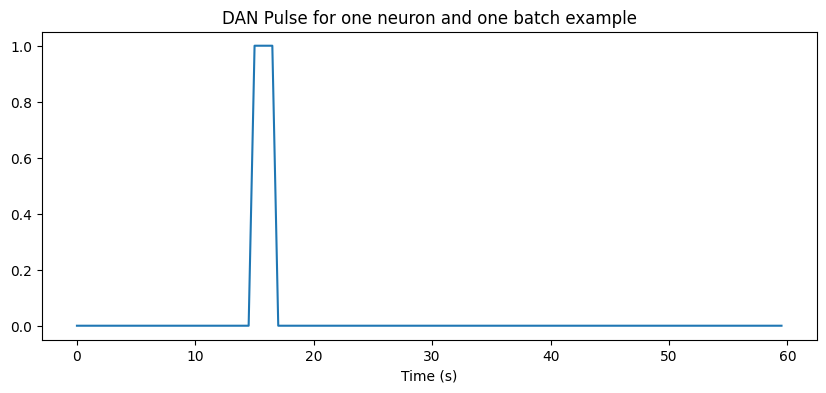

In [25]:
# Plot the DAN pulse for one batch
plt.figure(figsize=(10, 4))
plt.plot(time_range, pulse_dan[0, :, 0])
plt.title('DAN Pulse for one neuron and one batch example')
plt.xlabel('Time (s)')

In [ ]:
# Run an experience during time_range for each dT in dT_array
for dT_idx, dT in enumerate(dT_array):
    # Reset the KC pulse and weights for each dT
    pulse_kc = np.zeros((n_kc, len(time_range), batch_size))
    W = wmax*np.ones((n_mbon, n_dan, batch_size))

    # (Re)create the KC pulse for current dT
    t_kc_init = t_dan_init + dT 
    pulse_kc[:, int(t_kc_init/dt):int((t_kc_init + pulse_duration)/dt), :] = 1

    # TODO: HOW TO INITIALIZE rbar_kc and rbar_dan?
    
    # Run the experience for the current dT
    for t in time_range:
        r_dan = pulse_dan[:, int(t/dt)]
        r_kc = pulse_kc[:, int(t/dt)]
        W, rbar_kc, rbar_dan = update_kc_mbon_weights(W, r_kc, r_dan, rbar_kc, rbar_dan, dt, tau, tauw, wmax, stdpfac)
    dW_tot[dT_idx] = W - wmax*np.ones((n_mbon, n_dan, batch_size)) # TODO: is this truly the definition of dW ??



In [ ]:
# Plot dW as a function of dT